# Multiscale Organization in Sequence Representations - Learning Encodes Alignment within a Protein Family.

In this experiment, the authors investigate whether the unsupervised model implicitly learns evolutionary structural information typically identified by multiple sequence alignments (MSAs). Using MSAs from the Pfam database, they test the hypothesis that the model, despite having no access to the MSA during training, assigns similar representations to residues that align evolutionarily compared to those that do not.

To verify this, they compare the distribution of cosine similarities between "Aligned Pairs" (residues sharing evolutionary history) and a background distribution of "Unaligned Pairs".

# Setup & Imports

We prepare the environment and import the necessary modules, including the helper library to keep the code clean.

In [1]:
import os
import sys
import torch
import esm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
from Bio import AlignIO
from io import StringIO

# Ensure we can import from the parent directory
current_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(current_dir, ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from helpers import helper

# Reproducibility

In [2]:
SEED = 42
def set_seed(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)
print(f"Seed set to {SEED}. Ready to run.")

Seed set to 42. Ready to run.


# Load the Model

We load the esm1_t34_670M_UR100 (or equivalent smaller) model. We also create an "untrained" version of the model to serve as a baseline, allowing us to see what the model actually learned versus what is just random network noise.

In [3]:
# Load Pretrained Model (Using a smaller 6-layer model for demonstration speed)
# The paper uses the 34-layer ESM-1b model.
print("Loading Trained Model...")
model, alphabet = esm.pretrained.esm1_t34_670M_UR100()

if torch.cuda.is_available():
    model = model.cuda()
    print("Model moved to GPU.")

# Create Untrained Control Model (Randomized weights)
print("Creating Untrained Control Model...")
untrained_model = helper.randomize_model(model)
if torch.cuda.is_available():
    untrained_model = untrained_model.cuda()

Loading Trained Model...
Creating Untrained Control Model...


# Fetch & Process MSA Data

We use the Response regulator receiver domain (PF01010) as a representative family, just like in Figure 3 of the paper.

In [4]:
family_id = "PF01010"
print(f"Fetching MSA for {family_id}...")

# 1. Fetch MSA Data
msa_data = helper.get_pfam_seed_by_id(family_id)
if not msa_data:
    raise ValueError(f"Family {family_id} not found.")

# 2. Parse MSA
msa = AlignIO.read(StringIO(msa_data), "stockholm")
print(f"Loaded {msa[0].id} | Sequences: {len(msa)} | Length: {msa.get_alignment_length()}")

# 3. Clean & Map
# The model can't handle gaps, so we remove them but keep track of indices
clean_seqs, msa_mapping = helper.clean_and_map_msa(msa)
print(f"First sequence cleaned: {clean_seqs[0][:20]}...")

Fetching MSA for PF01010...
Streaming Pfam database to find PF01010...
This may take 1-2 minutes as it searches the compressed stream.
Loaded Q8HUX0_9ROSA/106-348 | Sequences: 76 | Length: 344
Processing 76 sequences...
First sequence cleaned: RIYLLTFEGHLNVHFQTYSG...


# Compute Representations

We run the sequences through both the Trained and Untrained models to get the hidden representations for every residue.

In [5]:
print("Computing representations (Forward Pass)...")

# Helper handles the batching and extraction of the final layer
token_reps_trained, token_reps_untrained = helper.forward_pass(
    clean_seqs, model, alphabet
)

print("Representations computed.")

Computing representations (Forward Pass)...
Processing 76 sequences in batches of 32 using multiprocessing...


100%|██████████| 3/3 [01:33<00:00, 31.27s/it]


Function 'get_hidden_representations' executed in 94.0386 seconds
Processing 76 sequences in batches of 32 using multiprocessing...


100%|██████████| 3/3 [01:12<00:00, 24.09s/it]

Function 'get_hidden_representations' executed in 72.4640 seconds
Representations computed.


# Calculate Similarities (The Experiment)

We sample pairs of residues that are aligned in the MSA and pairs that are unaligned. We then calculate the cosine similarity between their representations. We do this for three conditions :

Overall: All pairs.

Identical: Pairs where both amino acids are the same (e.g., A-A).

Distinct: Pairs where amino acids are different (e.g., A-V), to prove the model isn't just matching characters.

In [6]:
def get_cosine_similarities(msa, tokens, n_samples=50000, mode="all", print_stats=False):
    """
    Calculates cosine similarities for aligned vs unaligned residue pairs.
    """
    # Unpack representations
    token_reps_trained, token_reps_untrained = tokens
    
    # Clean and map MSA again to ensure consistency inside function
    clean_seqs, msa_mapping = helper.clean_and_map_msa(msa)

    # 1. Sample Aligned Pairs
    # 'mode' determines if we filter for identity, distinct, or all pairs
    aligned_pairs = helper.sample_aligned_pairs(
        msa_mapping, num_samples=n_samples, msa=msa, mode=mode
    )

    # 2. Sample Unaligned Pairs (Background distribution)
    # Uses aligned pairs to control for sequence distance
    unaligned_pairs = helper.sample_unaligned_pairs(aligned_pairs, msa_mapping)

    # MSA object is needed for "distinct" mode filtering during calculation
    msa_print = msa if mode == "distinct" else None

    if print_stats:
        print(f"Sampled {len(aligned_pairs)} aligned and {len(unaligned_pairs)} unaligned pairs.")

    # 3. Calculate Similarities for TRAINED Model
    print("  - Calculating Trained Similarities...")
    train_aligned_sim = helper.get_cosine_similarity(
        aligned_pairs, token_reps_trained, msa_mapping, msa_print
    )
    train_unaligned_sim = helper.get_cosine_similarity(
        unaligned_pairs, token_reps_trained, msa_mapping
    )

    # 4. Calculate Similarities for UNTRAINED Model
    print("  - Calculating Untrained Similarities...")
    untrain_aligned_sim = helper.get_cosine_similarity(
        aligned_pairs, token_reps_untrained, msa_mapping, msa_print
    )
    untrain_unaligned_sim = helper.get_cosine_similarity(
        unaligned_pairs, token_reps_untrained, msa_mapping
    )

    return (
        train_aligned_sim,
        train_unaligned_sim,
        untrain_aligned_sim,
        untrain_unaligned_sim,
    )

# Run the experiment for all three modes
print("Starting Similarity Experiments...")
results_all = get_cosine_similarities(msa, (token_reps_trained, token_reps_untrained), mode="all")
results_ident = get_cosine_similarities(msa, (token_reps_trained, token_reps_untrained), mode="identity")
results_distinct = get_cosine_similarities(msa, (token_reps_trained, token_reps_untrained), mode="distinct")
print("Experiments complete.")

Starting Similarity Experiments...
Processing 76 sequences...
all
  - Calculating Trained Similarities...
  - Calculating Untrained Similarities...
Processing 76 sequences...
identity
  - Calculating Trained Similarities...
  - Calculating Untrained Similarities...
Processing 76 sequences...
distinct
  - Calculating Trained Similarities...
  - Calculating Untrained Similarities...
Experiments complete.


# Visualization (Figure 3 Replication)

We plot the distributions. A successful model will show a large shift (separation) between the Aligned (Dark Blue) and Unaligned (Light Blue) distributions, while the Untrained model (Red) should show them overlapping

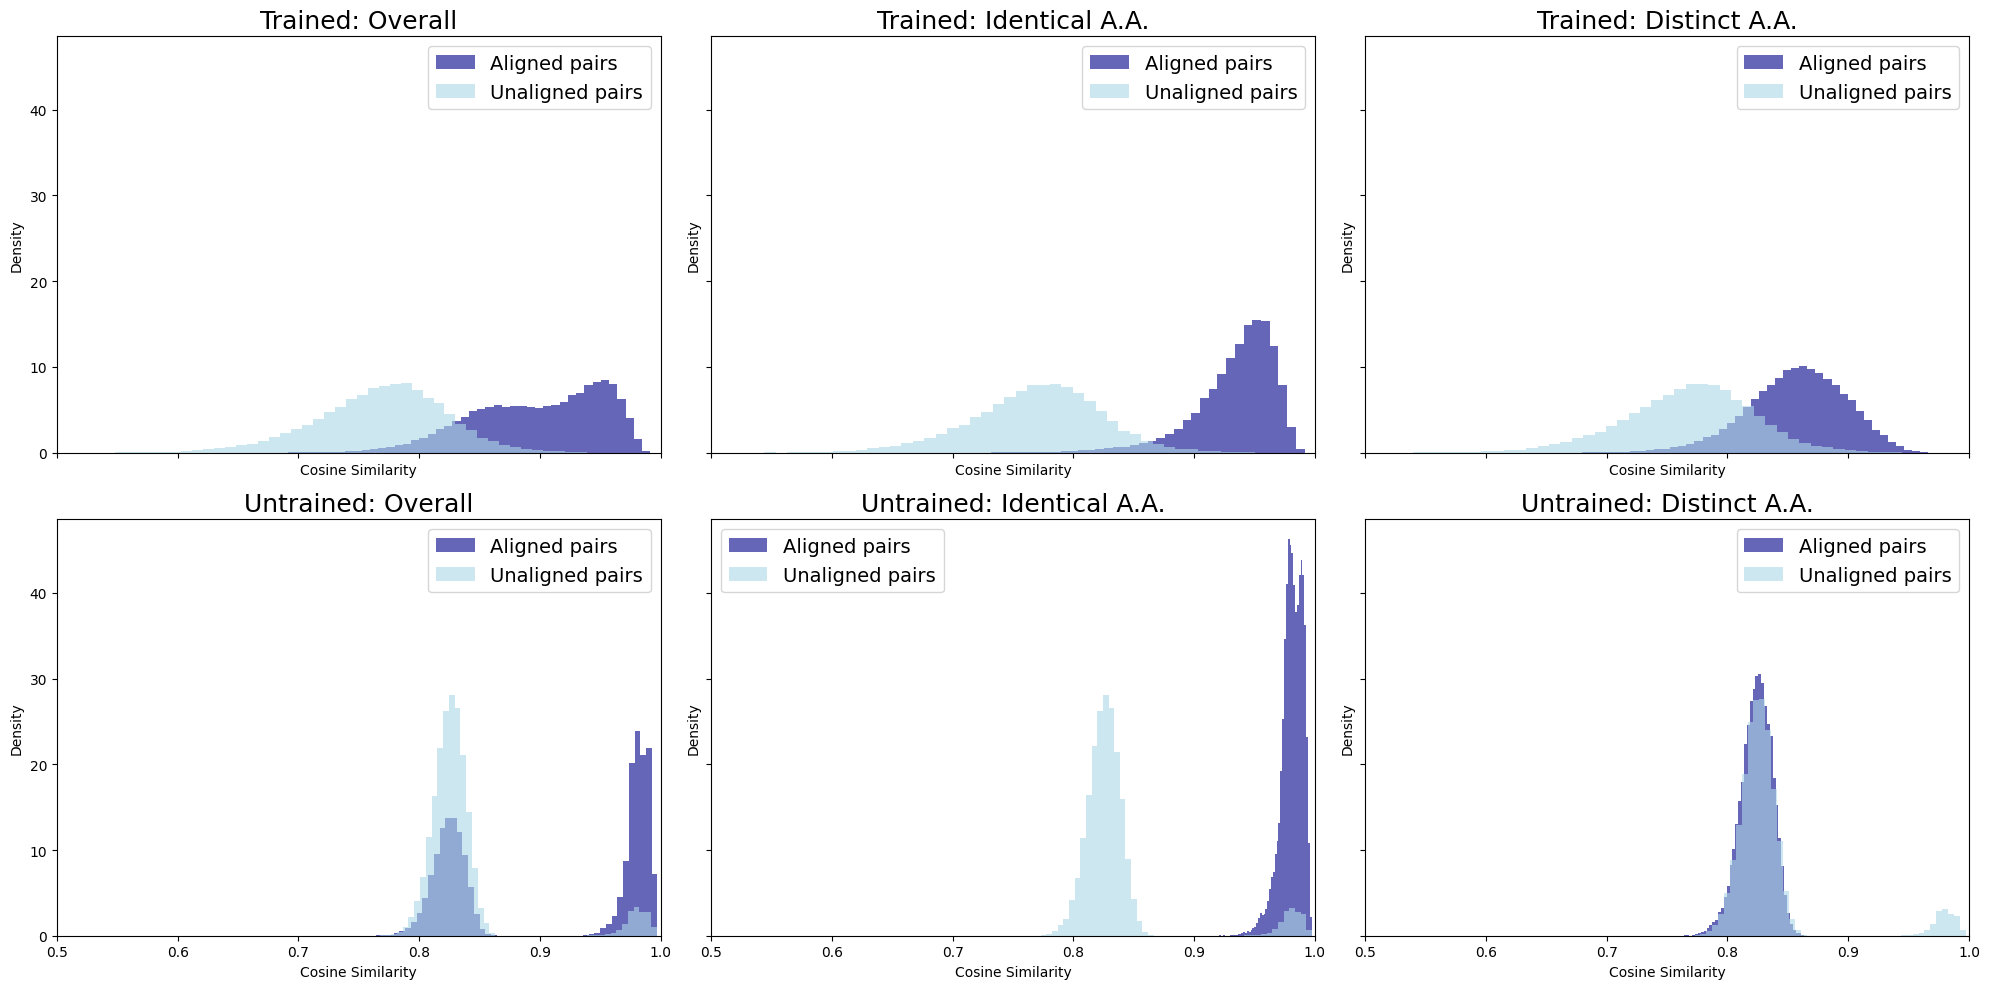

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10), sharey=True, sharex=True)

# Data organization for plotting
experiments = [
    (results_all, "Overall"),
    (results_ident, "Identical A.A."),
    (results_distinct, "Distinct A.A.")
]

for col, (results, title) in enumerate(experiments):
    tr_aligned, tr_unaligned, un_aligned, un_unaligned = results
    
    # Top Row: Trained Model (Blue)
    helper.plot_dist(axes[0][col], tr_aligned, tr_unaligned, f"Trained: {title}")
    
    # Bottom Row: Untrained Model (Red)
    helper.plot_dist(axes[1][col], un_aligned, un_unaligned, f"Untrained: {title}")

# Formatting
for ax in axes.flat:
    ax.set_xlim(0.5, 1)
    ax.set_ylabel("Density")
    ax.set_xlabel("Cosine Similarity")

plt.tight_layout()
plt.show()

# Quantification (AUC)

We calculate the Area Under the Curve (AUC) to quantify how well the representations distinguish aligned from unaligned residues

In [8]:
print(f"--- AUC Scores for {family_id} ---")

# Unpack results for "Overall" as an example
tr_aligned, tr_unaligned, un_aligned, un_unaligned = results_all

# Calculate AUC using helper
trained_auc, untrained_auc = helper.get_auc(
    tr_aligned, tr_unaligned, un_aligned, un_unaligned
)

print(f"Untrained AUC: {untrained_auc:.3f} (Baseline)")
print(f"Trained AUC:   {trained_auc:.3f} (Significant Improvement)")

--- AUC Scores for PF01010 ---
Untrained AUC: 0.724 (Baseline)
Trained AUC:   0.954 (Significant Improvement)
